# Import Libraries

In [1]:
# Common Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import warnings
import matplotlib.dates as mdates
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# LSTM Imports
from keras.models import Sequential
from keras.layers import LSTM, Dense, Input
from keras.optimizers import Adam
from keras.callbacks import LearningRateScheduler

# XGBoost Imports
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

# CNN Imports
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# Reading Dataset

## Solar Cycles durations

In [2]:
df_minima_maxima = pd.read_csv("minima_maxima.csv")
df_minima_maxima.head()

,cycle_number,min_year,min_month,minima,max_year,max_months,Maxima,duration_year,duration_month
0,1,1755,2,14.0,1761.0,6.0,144.1,11.0,4.0
1,2,1766,6,18.6,1769.0,9.0,193.0,9.0,0.0
2,3,1775,6,12.0,1778.0,5.0,264.2,9.0,3.0
3,4,1784,9,15.9,1788.0,2.0,235.3,13.0,7.0
4,5,1798,4,5.3,1805.0,2.0,82.0,12.0,3.0


## Monthly mean total sunspot number

In [3]:
column_names = ['year', 'month', 'fraction_date', 'mean_sunspot', 'mean_standard_deviation', 'number_of_observations',
                   'definitive_provisional']
df = pd.read_csv('SN_m_tot_V2.0.csv', sep=';', header=None, names=column_names)

# Convert numeric columns to appropriate data types
numeric_columns = ['year', 'month', 'fraction_date', 'mean_sunspot', 'mean_standard_deviation', 'number_of_observations',
                   'definitive_provisional']
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric)

df.head()

,year,month,fraction_date,mean_sunspot,mean_standard_deviation,number_of_observations,definitive_provisional
0,1749,1,1749.042,96.7,-1.0,-1,1
1,1749,2,1749.123,104.3,-1.0,-1,1
2,1749,3,1749.204,116.7,-1.0,-1,1
3,1749,4,1749.288,92.8,-1.0,-1,1
4,1749,5,1749.371,141.7,-1.0,-1,1


# Preprocessing

## Monthly mean total sunspot number

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3303 entries, 0 to 3302
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     3303 non-null   int64  
 1   month                    3303 non-null   int64  
 2   fraction_date            3303 non-null   float64
 3   mean_sunspot             3303 non-null   float64
 4   mean_standard_deviation  3303 non-null   float64
 5   number_of_observations   3303 non-null   int64  
 6   definitive_provisional   3303 non-null   int64  
dtypes: float64(3), int64(4)
memory usage: 180.8 KB


In [5]:
df.shape

(3303, 7)

### Filtered Data till solar cycle 24

In [6]:
filtered_df = df[(df['fraction_date'] >= 1755.123) & (df['fraction_date'] <= 2019.873)]
filtered_df.head()

,year,month,fraction_date,mean_sunspot,mean_standard_deviation,number_of_observations,definitive_provisional
73,1755,2,1755.123,18.7,-1.0,-1,1
74,1755,3,1755.204,11.3,-1.0,-1,1
75,1755,4,1755.288,10.8,-1.0,-1,1
76,1755,5,1755.371,0.0,-1.0,-1,1
77,1755,6,1755.455,0.0,-1.0,-1,1


### Combine month and year column

In [7]:
filtered_df['date_str'] = filtered_df['month'].astype(str) + '-' + filtered_df['year'].astype(str)

# Convert the concatenated string to datetime format
filtered_df['month_year'] = pd.to_datetime(filtered_df['date_str'], format='%m-%Y')

# Drop the intermediate string column
filtered_df.drop(columns=['date_str'], inplace=True)

filtered_df.head()

C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\1943533053.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['date_str'] = filtered_df['month'].astype(str) + '-' + filtered_df['year'].astype(str)
C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\1943533053.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['month_year'] = pd.to_datetime(filtered_df['date_str'], format='%m-%Y')
C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\1943533053.py:7: SettingWithCopyWar

,year,month,fraction_date,mean_sunspot,mean_standard_deviation,number_of_observations,definitive_provisional,month_year
73,1755,2,1755.123,18.7,-1.0,-1,1,1755-02-01
74,1755,3,1755.204,11.3,-1.0,-1,1,1755-03-01
75,1755,4,1755.288,10.8,-1.0,-1,1,1755-04-01
76,1755,5,1755.371,0.0,-1.0,-1,1,1755-05-01
77,1755,6,1755.455,0.0,-1.0,-1,1,1755-06-01


###  Dropping Columns

In [8]:
filtered_df.drop(['month', 'year', 'fraction_date', 'mean_standard_deviation', 'number_of_observations', 'definitive_provisional'], 
                 axis = 1, inplace=True)
filtered_df.head()

C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\3287042886.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop(['month', 'year', 'fraction_date', 'mean_standard_deviation', 'number_of_observations', 'definitive_provisional'], axis = 1, inplace=True)


,mean_sunspot,month_year
73,18.7,1755-02-01
74,11.3,1755-03-01
75,10.8,1755-04-01
76,0.0,1755-05-01
77,0.0,1755-06-01


### Formatting and Sorting Time-Series Data by Month and Year

In [9]:
filtered_df['month_year'] = pd.to_datetime(filtered_df['month_year'], format='%m-%Y')
filtered_df['month_year'] = filtered_df['month_year'].dt.strftime('%Y-%m')
filtered_df = filtered_df.sort_values(by='month_year')
df = filtered_df.set_index('month_year')
df.head()

C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\798218529.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['month_year'] = pd.to_datetime(filtered_df['month_year'], format='%m-%Y')
C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\798218529.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['month_year'] = filtered_df['month_year'].dt.strftime('%Y-%m')


,mean_sunspot
month_year,
1755-02,18.7
1755-03,11.3
1755-04,10.8
1755-05,0.0
1755-06,0.0


## Solar Cycle Duration

In [10]:
df_minima_maxima['max_year'] = df_minima_maxima['max_year'].replace('', np.nan)
df_minima_maxima['max_months'] = df_minima_maxima['max_months'].replace('', np.nan)

In [11]:
df_minima_maxima['max_year'] = df_minima_maxima['max_year'].fillna(-1).astype(int)  # Assuming -1 indicates missing values
df_minima_maxima['max_months'] = df_minima_maxima['max_months'].fillna(-1).astype(int)

# Ensure that date components are integers and handle cases where data might be invalid
df_minima_maxima['Minima_Date'] = pd.to_datetime(
    df_minima_maxima.apply(lambda row: f"{int(row['min_year'])}-{int(row['min_month']):02d}-01", axis=1),
    errors='coerce'
)
df_minima_maxima['Maxima_Date'] = pd.to_datetime(
    df_minima_maxima.apply(lambda row: f"{int(row['max_year'])}-{int(row['max_months']):02d}-01", axis=1),
    errors='coerce'
)

df_minima_maxima.head()

,cycle_number,min_year,min_month,minima,max_year,max_months,Maxima,duration_year,duration_month,Minima_Date,Maxima_Date
0,1,1755,2,14.0,1761,6,144.1,11.0,4.0,1755-02-01,1761-06-01
1,2,1766,6,18.6,1769,9,193.0,9.0,0.0,1766-06-01,1769-09-01
2,3,1775,6,12.0,1778,5,264.2,9.0,3.0,1775-06-01,1778-05-01
3,4,1784,9,15.9,1788,2,235.3,13.0,7.0,1784-09-01,1788-02-01
4,5,1798,4,5.3,1805,2,82.0,12.0,3.0,1798-04-01,1805-02-01


In [12]:
df_cycles = df_minima_maxima[df_minima_maxima['cycle_number'] <= 24]

df_cycles['duration_year'] = df_cycles['duration_year'].fillna(-1).astype(int)  # Assuming -1 indicates missing values
df_cycles['duration_month'] = df_cycles['duration_month'].fillna(-1).astype(int)

df_cycles.head()

C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\3983993197.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cycles['duration_year'] = df_cycles['duration_year'].fillna(-1).astype(int)  # Assuming -1 indicates missing values
C:\Users\Asad Naseer\AppData\Local\Temp\ipykernel_17020\3983993197.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cycles['duration_month'] = df_cycles['duration_month'].fillna(-1).astype(int)


,cycle_number,min_year,min_month,minima,max_year,max_months,Maxima,duration_year,duration_month,Minima_Date,Maxima_Date
0,1,1755,2,14.0,1761,6,144.1,11,4,1755-02-01,1761-06-01
1,2,1766,6,18.6,1769,9,193.0,9,0,1766-06-01,1769-09-01
2,3,1775,6,12.0,1778,5,264.2,9,3,1775-06-01,1778-05-01
3,4,1784,9,15.9,1788,2,235.3,13,7,1784-09-01,1788-02-01
4,5,1798,4,5.3,1805,2,82.0,12,3,1798-04-01,1805-02-01


## EDA

### Mean Sunspot Number over the years

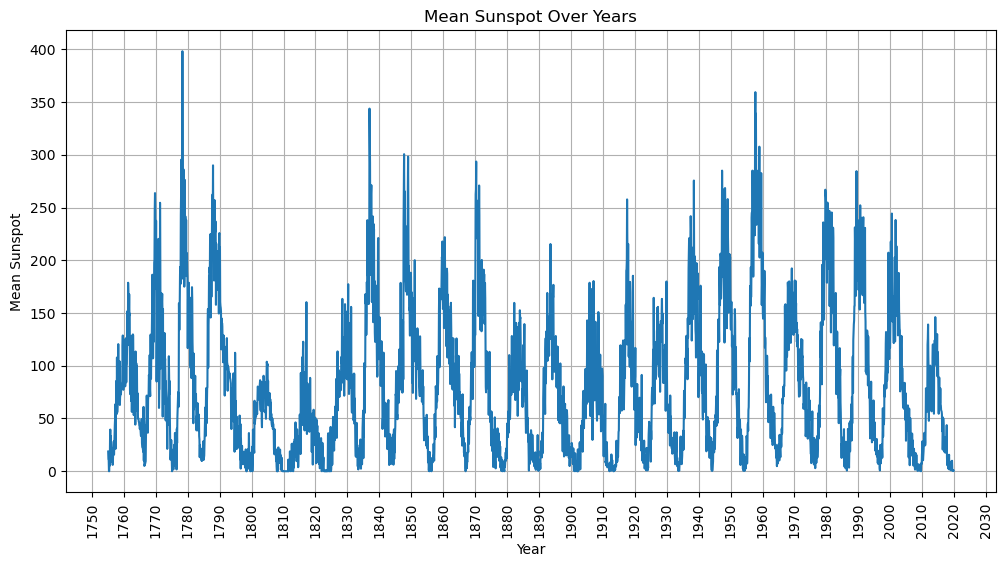

In [13]:
df.index = pd.to_datetime(df.index, format='%Y-%m')

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['mean_sunspot'], linestyle='-')
plt.xlabel('Year')
plt.ylabel('Mean Sunspot')
plt.title('Mean Sunspot Over Years')

# Set the major locator to 10-year intervals
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Add grid for better visualization
plt.grid(True)

# Display the plot
plt.show()

The graph shows changes in mean sunspot numbers from 1750 to around 2030, emphasizing the cyclical pattern of solar activity with peaks roughly every 11 years. High solar activity periods are indicated by noticeable peaks, while low activity periods, like the Dalton Minimum, appear as dips. The decline in sunspot numbers around the early 2020s suggests a period of decreased solar activity. This regular pattern helps in creating models to predict future solar activity, which is important for space weather forecasts and protecting technological systems.

### Solar Cycle Maxima and Minima

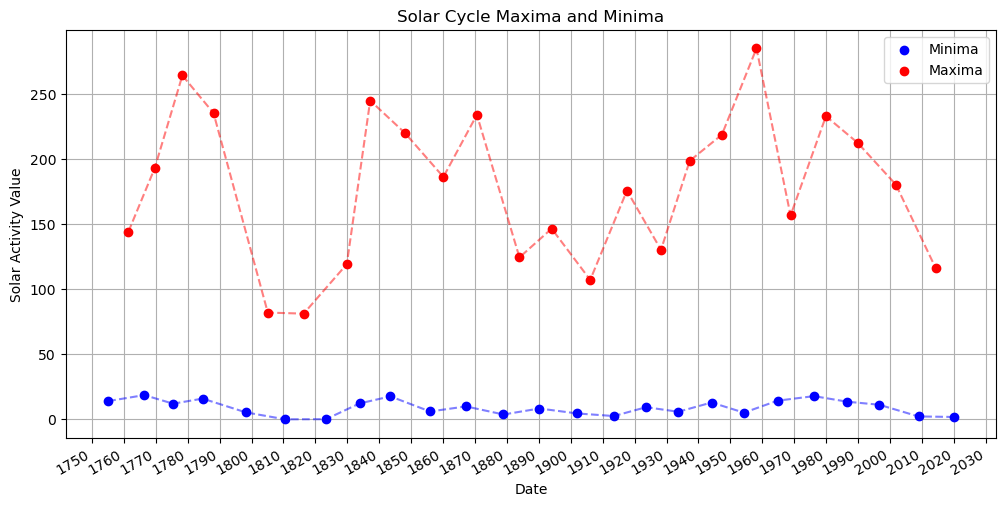

In [14]:
# Plot
plt.figure(figsize=(12, 6))

# Plot minima
plt.scatter(df_minima_maxima['Minima_Date'], df_minima_maxima['minima'], color='blue', label='Minima', zorder=5)
plt.plot(df_minima_maxima['Minima_Date'], df_minima_maxima['minima'], color='blue', linestyle='--', alpha=0.5, zorder=4)

# Plot maxima
plt.scatter(df_minima_maxima['Maxima_Date'], df_minima_maxima['Maxima'], color='red', label='Maxima', zorder=5)
plt.plot(df_minima_maxima['Maxima_Date'], df_minima_maxima['Maxima'], color='red', linestyle='--', alpha=0.5, zorder=4)

# Formatting
plt.xlabel('Date')
plt.ylabel('Solar Activity Value')
plt.title('Solar Cycle Maxima and Minima')
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(10))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gcf().autofmt_xdate()

# Show plot
plt.savefig("max_min.png")

The graph shows the highest and lowest points of solar activity from 1750 to around 2030. The red dots and dashed line represent the peaks (maxima) in solar activity, while the blue dots and dashed line show the lowest points (minima). The pattern demonstrates regular changes in solar activity, with each cycle lasting about 11 years. The peaks vary significantly in intensity, while the low points stay more consistent over time. This predictable pattern is important for forecasting solar activity.

### Solar Cycle Duration by Cycle Number

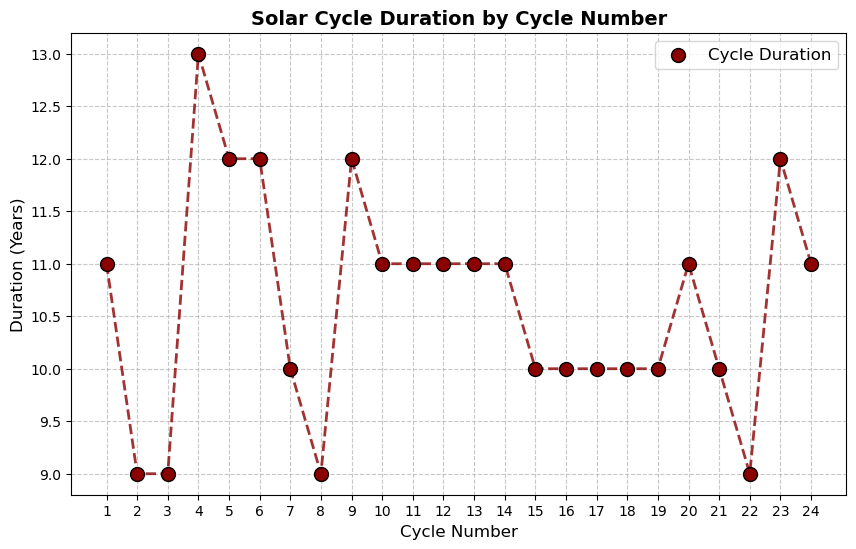

In [15]:
plt.figure(figsize=(10, 6))

# Scatter plot with enhanced markers
plt.scatter(df_cycles['cycle_number'], df_cycles['duration_year'], 
            color='darkred', edgecolor='black', s=100, label='Cycle Duration', zorder=5)

# Line plot with improved line style and color
plt.plot(df_cycles['cycle_number'], df_cycles['duration_year'], 
         color='darkred', linestyle='--', linewidth=2, alpha=0.8, zorder=4)

# Enhancements
plt.title('Solar Cycle Duration by Cycle Number', fontsize=14, fontweight='bold')
plt.xlabel('Cycle Number', fontsize=12)
plt.ylabel('Duration (Years)', fontsize=12)
plt.xticks(df_cycles['cycle_number'], fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

# Show plot
plt.show()

The graph shows the duration of each solar cycle from Cycle 1 to Cycle 24. Each point represents the length of a specific cycle in years. The duration of solar cycles varies, with some cycles lasting around 9 years and others extending up to 13 years. The pattern indicates fluctuations in cycle length rather than a consistent duration. Understanding these variations is important for accurately predicting future solar cycles and preparing for their effects on Earth's technological systems and climate.

# Models

## LSTM

In [16]:
def create_dataset(data, n_steps):
    """
    Create a dataset for time series prediction by generating sequences of data.

    Parameters:
    data (np.array): Input time series data as a 1D numpy array.
    n_steps (int): Number of time steps to use for each sample.

    Returns:
    tuple: A tuple (X, y) where:
        - X (np.array): A 2D numpy array of shape (num_samples, n_steps) containing the input features.
        - y (np.array): A 1D numpy array of shape (num_samples,) containing the target values.

    Raises:
    ValueError: If there is not enough data to create the dataset (i.e., fewer than n_steps + 1 samples).
    """
    X, y = [], []
    for i in range(len(data) - n_steps):
        sequence = data[i:i + n_steps]
        target = data[i + n_steps]
        if len(sequence) == n_steps:  # Ensure consistent length
            X.append(sequence)
            y.append(target)
    
    X, y = np.array(X), np.array(y)
    
    if X.size == 0:
        raise ValueError("Not enough data to create dataset")

    return X, y

In [17]:
def lr_scheduler(epoch, lr):
    """
    Learning rate scheduler function to adjust the learning rate based on the epoch.

    Parameters:
    epoch (int): The current epoch number.
    lr (float): The current learning rate.

    Returns:
    float: The adjusted learning rate for the current epoch.
    """
    drop_period = 125
    drop_factor = 0.2
    if epoch % drop_period == 0 and epoch != 0:
        return lr * drop_factor
    return lr

In [18]:
# Function to initialize and train the LSTM model
def train_lstm_model(input_shape, X_train, y_train, epochs=100, batch_size=32, validation_split=0.2):
    """
    Initializes and trains an LSTM model.
    
    Args:
        input_shape (tuple): Shape of the input data.
        X_train (np.array): Training input data.
        y_train (np.array): Training target data.
        epochs (int, optional): Number of training epochs. Defaults to 200.
        batch_size (int, optional): Batch size for training. Defaults to 64.
        validation_split (float, optional): Fraction of training data to use for validation. Defaults to 0.2.
    
    Returns:
        keras.Model: Trained LSTM model.
    """
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(LSTM(50, activation='relu', return_sequences=True))
    model.add(Dropout(0.2))  # Add Dropout layer with a dropout rate of 20%
    model.add(LSTM(50, activation='relu'))
    model.add(Dropout(0.2))  # Add another Dropout layer with a dropout rate of 20%
    model.add(Dense(1))
    
    # Create the Adam optimizer with the specified initial learning rate and gradient clipping
    initial_lr = 0.005
    optimizer = Adam(learning_rate=initial_lr, clipvalue=1.0)
    
    # Compile the model with the optimizer
    model.compile(optimizer=optimizer, loss='mse')
    
    # Create a learning rate scheduler callback
    lr_callback = LearningRateScheduler(lr_scheduler)
    
    # Train the model with the learning rate scheduler
    model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=validation_split, callbacks=[lr_callback])
    
    return model

In [19]:
def plot_training_data(train_data, test_data):
    """
    Plots the training and testing data on a time series graph.

    Args:
        train_data (pd.DataFrame): DataFrame containing the training data with 'mean_sunspot' and datetime index.
        test_data (pd.DataFrame): DataFrame containing the testing data with 'mean_sunspot' and datetime index.

    Returns:
        None: This function only generates a plot and does not return any value.
    """
    plt.figure(figsize=(12, 6))
    plt.plot(train_data.index, train_data['mean_sunspot'], label='Train Data')
    plt.plot(test_data.index, test_data['mean_sunspot'], label='Test Data')
    plt.xlabel('Date')
    plt.ylabel('Mean Sunspot')
    plt.title('Training and Testing Data')
    plt.legend()
    plt.show()

In [20]:
def plot_results(model_name, foldername, sam_df, train_index, test_index, train_predict, test_predict, future_dates, forecast, n_forecast, split_count, test_rmse, n_steps):
    """
    Plots and saves the comparison of actual, predicted, and forecasted values for LSTM model results.

    Args:
        foldername (str): Directory where the plot image will be saved.
        sam_df (pd.DataFrame): DataFrame containing the time series data with 'mean_sunspot' and datetime index.
        train_index (np.array): Indices of the training data within `sam_df`.
        test_index (np.array): Indices of the test data within `sam_df`.
        train_predict (np.array): Predicted values for the training data.
        test_predict (np.array): Predicted values for the test data.
        future_dates (pd.DatetimeIndex): Dates corresponding to the forecasted values.
        forecast (np.array): Forecasted values for the future dates.
        n_forecast (int): Number of forecast steps ahead.
        split_count (int): Index or count of the data split being plotted.
        test_rmse (float): Root Mean Squared Error of the test predictions.
        n_steps (int): Number of time steps used in the model.

    Returns:
        None: This function generates and saves a plot but does not return any value.
    """
    plt.figure(figsize=(12, 6))
    plt.title(f'{model_name} Actual vs Predicted vs Forecasted Values (n_steps={n_steps}) and Split {split_count}')
    plt.xlabel('Date')
    plt.ylabel('Mean Sunspot')
    
    plt.plot(sam_df.index[train_index], sam_df['mean_sunspot'].iloc[train_index], color='blue', label='Train Actual')
    plt.plot(sam_df.index[test_index], sam_df['mean_sunspot'].iloc[test_index], color='red', label='Test Actual')

    try:
        plt.plot(sam_df.index[train_index[n_forecast:]], train_predict.flatten(), color='cyan', label='Train Predict')
        plt.plot(sam_df.index[test_index[n_forecast:]], test_predict.flatten(), color='magenta', label='Test Predict')
    except ValueError as e:
        print(f"An error occurred during calculation of testing index: {e}")
    
    plt.plot(future_dates, forecast, color='green', marker='o', linestyle='dashed', label='Forecast')
    
    plt.legend()
    plt.grid(True)  # Add grid for better visualization
    path = f"{foldername}/{n_steps}_{split_count}_{test_rmse:.2f}.png"
    plt.savefig(path)
    plt.show()

In [21]:
def calculate_lstm(train_data, test_data, column_name, n_steps, n_forecast, split_count):
    """
    Trains an LSTM model on the given training data, evaluates its performance on test data, and makes forecasts.

    Args:
        train_data (pd.DataFrame or np.array): Training dataset containing the time series data.
        test_data (pd.DataFrame or np.array): Test dataset containing the time series data.
        column_name (str): The name of the column containing the time series values.
        n_steps (int): Number of time steps used to create the input sequences for the LSTM model.
        n_forecast (int): Number of future time steps to forecast.
        split_count (int): Identifier for the data split being processed.

    Returns:
        None: This function performs training, evaluation, and forecasting, and generates plots but does not return any value.
    
    Notes:
        - Scales the input data using MinMaxScaler.
        - Reshapes the input data to be compatible with the LSTM model.
        - Evaluates the model's performance using RMSE and MAPE metrics.
        - Saves the plots of training, testing, and forecasted values to disk.
    """
    # Scale the data
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_data)
    scaled_train_data = scaler.transform(train_data)
    scaled_test_data = scaler.transform(test_data)
    print("Scale train Dataset: ", len(scaled_train_data))
    print("Scale test Dataset: ", len(scaled_test_data))

    plot_training_data(train_data, test_data)
    
    X_train, y_train = create_dataset(scaled_train_data, n_forecast)
    X_test, y_test = create_dataset(scaled_test_data, n_forecast)
    
    # Debug prints to understand the shapes of the datasets
    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape: {X_test.shape}")
    print(f"y_test shape: {y_test.shape}")
    
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        print("Insufficient data for creating the dataset.")
        return

    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

    model = train_lstm_model((n_steps, 1), X_train, y_train)

    train_predict = model.predict(X_train)
    test_predict = model.predict(X_test)

    train_predict = scaler.inverse_transform(train_predict)
    y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
    test_predict = scaler.inverse_transform(test_predict)
    y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

    train_rmse = np.sqrt(mean_squared_error(y_train_inv, train_predict))
    test_rmse = np.sqrt(mean_squared_error(y_test_inv, test_predict))
    
    test_mape = mean_absolute_percentage_error(y_test_inv, test_predict) * 100
    
    print(f"Split {split_count} - Test RMSE: {test_rmse}")
    print(f"Split {split_count} - Test MAPE: {test_mape:.2f}%\n")


    forecast = []
    last_sequence = scaled_test_data[-n_forecast:]
    current_sequence = last_sequence.reshape((1, n_forecast, 1))

    for _ in range(n_forecast):
        next_value = model.predict(current_sequence)
        forecast.append(next_value[0, 0])
        current_sequence = np.append(current_sequence[:, 1:, :], next_value.reshape((1, 1, 1)), axis=1)

    forecast = scaler.inverse_transform(np.array(forecast).reshape(-1, 1))

    last_date = test_data.index[-1]
    future_dates = pd.date_range(start=last_date + pd.DateOffset(1), periods=n_forecast, freq='M')

    train_index = range(len(train_data))
    test_index = range(len(train_data), len(train_data) + len(test_data))
    
    plot_results("LSTM", "lstm_final", df, train_index, test_index, train_predict, test_predict, future_dates, forecast, n_forecast, split_count, test_rmse, n_steps)

## XG Boost

In [22]:
def create_dataset(dataset, n_forecast):
    """
    Prepares a dataset for time series forecasting by creating input-output sequences.

    Args:
        dataset (np.array): The input time series data, where each row is a time step and the second dimension is the feature column.
        n_forecast (int): The number of time steps used to create the input sequences for forecasting.

    Returns:
        tuple: (X, y)
            - X (np.array): The input sequences of shape (num_samples, n_forecast), where each sample contains `n_forecast` time steps.
            - y (np.array): The target values of shape (num_samples,), where each value is the forecasted value for the time step following the input sequence.
    """
    X, y = [], []
    for i in range(len(dataset) - n_forecast):
        X.append(dataset[i:i + n_forecast, 0])
        y.append(dataset[i + n_forecast, 0])
    return np.array(X), np.array(y)

In [23]:
def calculate_xgboost(train_data, test_data, column_name, n_steps, n_forecast, split_count):
    """
    Trains an XGBoost model and makes forecasts on time series data.

    Args:
        train_data (pd.DataFrame): The training dataset containing time series data.
        test_data (pd.DataFrame): The test dataset containing time series data.
        column_name (str): The column name of the target variable in the datasets.
        n_steps (int): The number of time steps used for each input sequence.
        n_forecast (int): The number of future time steps to forecast.
        split_count (int): Identifier for the current data split, used for naming and tracking results.

    Returns:
        None: The function saves plots and prints results, but does not return any values.

    """
    # Scale the data
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_data)
    scaled_train_data = scaler.transform(train_data)
    scaled_test_data = scaler.transform(test_data)
    print("Scale train Dataset: ", len(scaled_train_data))
    print("Scale test Dataset: ", len(scaled_test_data))
    
    X_train, y_train = create_dataset(scaled_train_data, n_forecast)
    X_test, y_test = create_dataset(scaled_test_data, n_forecast)
    
    # Debug prints to understand the shapes of the datasets
    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape: {X_test.shape}")
    print(f"y_test shape: {y_test.shape}")
    
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        print("Insufficient data for creating the dataset.")
        return

    # Reshape data to be compatible with XGBoost (1D arrays)
    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1]))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1]))

    # Define the XGBoost model
    model = XGBRegressor(objective='reg:squarederror', eval_metric='rmse')

    # Define the hyperparameters grid
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.1, 0.3],
        'subsample': [0.8, 1.0]
    }

    # Grid search for hyperparameter tuning
    grid_search = GridSearchCV(estimator=model, param_grid=param_grid, scoring='neg_mean_squared_error', cv=3, verbose=1)
    grid_search.fit(X_train, y_train)

    # Best model from grid search
    best_model = grid_search.best_estimator_
    print(f"Best parameters found: {grid_search.best_params_}")

    # Make predictions
    train_predict = best_model.predict(X_train)
    test_predict = best_model.predict(X_test)

    # Inverse transform the predictions
    train_predict = scaler.inverse_transform(train_predict.reshape(-1, 1))
    y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
    test_predict = scaler.inverse_transform(test_predict.reshape(-1, 1))
    y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

    # Calculate RMSE and MAPE
    train_rmse = np.sqrt(mean_squared_error(y_train_inv, train_predict))
    test_rmse = np.sqrt(mean_squared_error(y_test_inv, test_predict))
    test_mape = mean_absolute_percentage_error(y_test_inv, test_predict) * 100

    print(f"Split {split_count} - Test RMSE: {test_rmse}")
    print(f"Split {split_count} - Test MAPE: {test_mape:.2f}%\n")

    # Forecasting
    forecast = []
    last_sequence = scaled_test_data[-n_forecast:]
    current_sequence = last_sequence.reshape((1, n_forecast))

    for _ in range(n_forecast):
        next_value = best_model.predict(current_sequence)
        forecast.append(next_value[0])
        current_sequence = np.append(current_sequence[:, 1:], next_value.reshape(1, 1), axis=1)

    forecast = scaler.inverse_transform(np.array(forecast).reshape(-1, 1))

    last_date = test_data.index[-1]
    future_dates = pd.date_range(start=last_date + pd.DateOffset(1), periods=n_forecast, freq='M')

    train_index = range(len(train_data))
    test_index = range(len(train_data), len(train_data) + len(test_data))
    
    plot_xgboost_results("xg_boost_final", df, train_index, test_index, train_predict, test_predict, future_dates, forecast, n_forecast, split_count, test_rmse, n_steps)

In [24]:
def plot_xgboost_results(foldername, sam_df, train_index, test_index, train_predict, test_predict, future_dates, forecast, n_forecast, split_count, test_rmse, n_steps):
    plt.figure(figsize=(12, 6))
    plt.title(f'XG Boost Actual vs Predicted vs Forecasted Values (n_steps={n_steps}) and Split {split_count}')
    plt.xlabel('Date')
    plt.ylabel('Mean Sunspot')
    
    plt.plot(sam_df.index[train_index], sam_df['mean_sunspot'].iloc[train_index], color='blue', label='Train Actual')
    plt.plot(sam_df.index[test_index], sam_df['mean_sunspot'].iloc[test_index], color='red', label='Test Actual')

    try:
        plt.plot(sam_df.index[train_index[n_forecast:]], train_predict.flatten(), color='cyan', label='Train Predict')
        plt.plot(sam_df.index[test_index[n_forecast:]], test_predict.flatten(), color='magenta', label='Test Predict')
    except ValueError as e:
        print(f"An error occurred during calculation of predicting value: {e}")
    
    plt.plot(future_dates, forecast, color='green', marker='o', linestyle='dashed', label='Forecast')
    
    plt.legend()
    plt.grid(True)  # Add grid for better visualization
    path = f"{foldername}/{n_steps}_{split_count}_{test_rmse:.2f}.png"
    plt.savefig(path)
    plt.show()

## CNN

In [25]:
def build_cnn_model(input_shape, filters=64, kernel_size=2, pool_size=2, dense_units=50, dropout_rate=0.2, learning_rate=0.001):
    """
    Builds a 1D Convolutional Neural Network (CNN) model for regression tasks.

    Args:
        input_shape (tuple): Shape of the input data (timesteps, features). For example, (n_steps, 1).
        filters (int, optional): Number of filters in the Conv1D layer. Default is 64.
        kernel_size (int, optional): Size of the convolutional kernel. Default is 2.
        pool_size (int, optional): Size of the pooling window. Default is 2.
        dense_units (int, optional): Number of units in the dense layer. Default is 50.
        dropout_rate (float, optional): Dropout rate for regularization. Default is 0.2.
        learning_rate (float, optional): Learning rate for the Adam optimizer. Default is 0.001.

    Returns:
        tf.keras.Model: Compiled 1D CNN model.
    """
    model = Sequential()
    model.add(Input(shape=input_shape))  # Explicitly specify the input shape here
    model.add(Conv1D(filters=filters, kernel_size=kernel_size, activation='relu'))
    model.add(MaxPooling1D(pool_size=pool_size))
    model.add(Dropout(dropout_rate))
    model.add(Flatten())
    model.add(Dense(dense_units, activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))
    
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    
    return model

In [26]:
def train_cnn_model(X_train, y_train, batch_size=32, epochs=50):
    """
    Initializes and trains a 1D Convolutional Neural Network (CNN) model on the provided training data.

    Args:
        X_train (np.array): Training input data with shape (num_samples, timesteps, features).
        y_train (np.array): Training target data with shape (num_samples,).
        batch_size (int, optional): Number of samples per gradient update. Default is 32.
        epochs (int, optional): Number of epochs to train the model. Default is 50.

    Returns:
        tf.keras.Model: Trained 1D CNN model.
    """
    input_shape = (X_train.shape[1], X_train.shape[2])  # Define the input shape based on your data
    model = build_cnn_model(
        input_shape=input_shape,
        filters=64,
        kernel_size=2,
        pool_size=2,
        dense_units=50,
        dropout_rate=0.2,
        learning_rate=0.001
    )
    
    model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, verbose=1)
    
    return model

In [27]:
def calculate_cnn(train_data, test_data, column_name, n_steps, n_forecast, split_count):
    """
    Trains a 1D Convolutional Neural Network (CNN) on the provided training data and makes forecasts.

    Args:
        train_data (pd.DataFrame): The training dataset with a time series column.
        test_data (pd.DataFrame): The testing dataset with a time series column.
        column_name (str): The name of the column in the data to be used for training and testing.
        n_steps (int): Number of time steps to look back in the dataset to predict the next value.
        n_forecast (int): Number of future time steps to forecast.
        split_count (int): Identifier for the current data split or experiment.

    Returns:
        None
    """
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_data)
    scaled_train_data = scaler.transform(train_data)
    scaled_test_data = scaler.transform(test_data)
    print("Scaled train Dataset: ", len(scaled_train_data))
    print("Scaled test Dataset: ", len(scaled_test_data))
    
    X_train, y_train = create_dataset(scaled_train_data, n_steps)
    X_test, y_test = create_dataset(scaled_test_data, n_steps)
    
    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape: {X_test.shape}")
    print(f"y_test shape: {y_test.shape}")
    
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        print("Insufficient data for creating the dataset.")
        return

    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

    # Train the model
    batch_size = 32
    epochs = 100
    model = train_cnn_model(X_train, y_train, batch_size, epochs)

    # Make predictions
    train_predict = model.predict(X_train)
    test_predict = model.predict(X_test)

    # Inverse transform the predictions and true values
    train_predict = scaler.inverse_transform(train_predict.reshape(-1, 1))
    y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
    test_predict = scaler.inverse_transform(test_predict.reshape(-1, 1))
    y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

    # Calculate metrics
    train_rmse = np.sqrt(mean_squared_error(y_train_inv, train_predict))
    test_rmse = np.sqrt(mean_squared_error(y_test_inv, test_predict))
    test_mape = mean_absolute_percentage_error(y_test_inv, test_predict) * 100
    
    print(f"Split {split_count} - Test RMSE: {test_rmse}")
    print(f"Split {split_count} - Test MAPE: {test_mape:.2f}%\n")

    # Forecasting
    forecast = []
    last_sequence = scaled_test_data[-n_steps:]
    current_sequence = last_sequence.reshape((1, n_steps, 1))

    for _ in range(n_forecast):
        next_value = model.predict(current_sequence)
        forecast.append(next_value[0])
        current_sequence = np.append(current_sequence[:, 1:, :], next_value.reshape((1, 1, 1)), axis=1)

    forecast = scaler.inverse_transform(np.array(forecast).reshape(-1, 1))

    # Generate future dates
    last_date = test_data.index[-1]
    future_dates = pd.date_range(start=last_date + pd.DateOffset(1), periods=n_forecast, freq='M')

    # Assume plot_results is defined elsewhere
    train_index = range(len(train_data))
    test_index = range(len(train_data), len(train_data) + len(test_data))
    plot_results("CNN", "cnn_final", df, train_index, test_index, train_predict, test_predict, future_dates, forecast, n_forecast, split_count, test_rmse, n_steps)

# Main File

In [28]:
first_date = df.index.min()
last_date = df.index.max()
total_num_months = (last_date.year - first_date.year) * 12 + last_date.month - first_date.month
total_num_months

3177

In [29]:
def sample_size(years_sample, total_num_months):
    total_months_sample = years_sample * 12
    initial_size = (years_sample * 4 * 12) + (total_num_months % total_months_sample)
    return initial_size

-----------------------------------1-----------------------------------
Scale train Dataset:  537
Scale test Dataset:  240


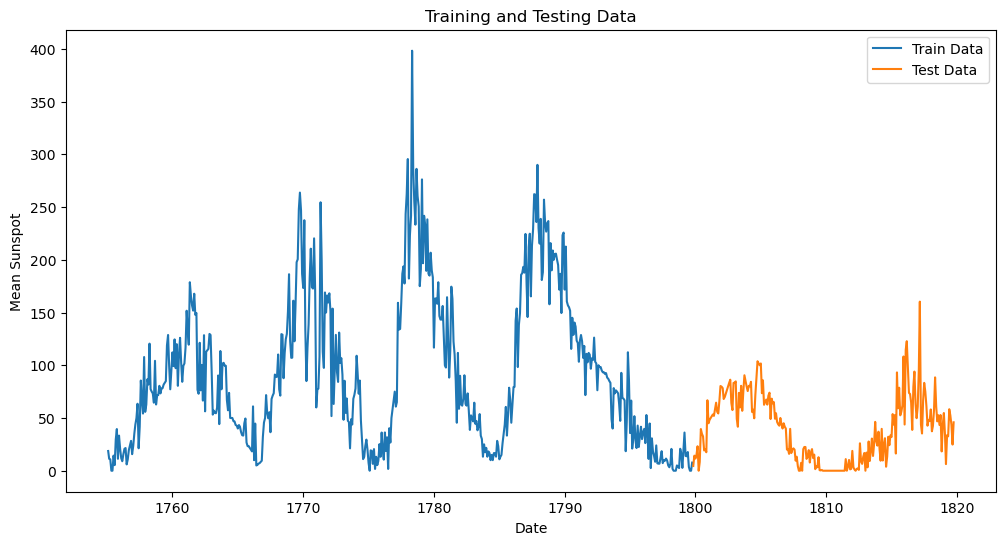

X_train shape: (417, 120)
y_train shape: (417,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 172ms/step - loss: 0.0810 - val_loss: 0.0087 - learning_rate: 0.0050
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - loss: 0.0290 - val_loss: 0.0169 - learning_rate: 0.0050
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.0173 - val_loss: 0.0027 - learning_rate: 0.0050
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - loss: 0.0140 - val_loss: 0.0055 - learning_rate: 0.0050
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0120 - val_loss: 0.0064 - learning_rate: 0.0050
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - loss: 0.0124 - val_loss: 0.0039 - learning_rate: 0.0050
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0098 - val_loss: 0.0035 - learning_rate: 0.0050
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - loss: 0.0100 - val_loss: 0.0025 - learning_rate: 0.0050
Epoch 9/100
11/11 ━━━

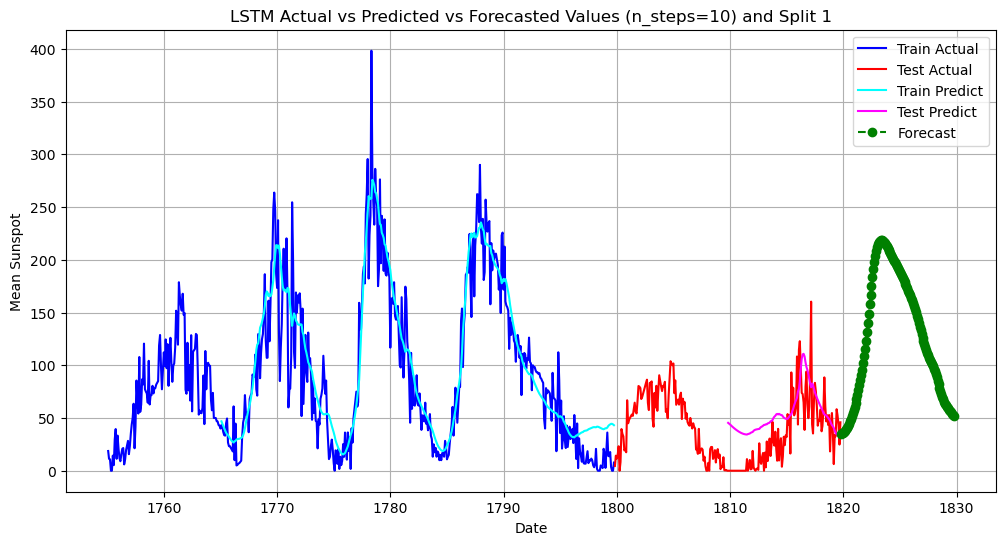

-----------------------------------2-----------------------------------
Scale train Dataset:  657
Scale test Dataset:  240


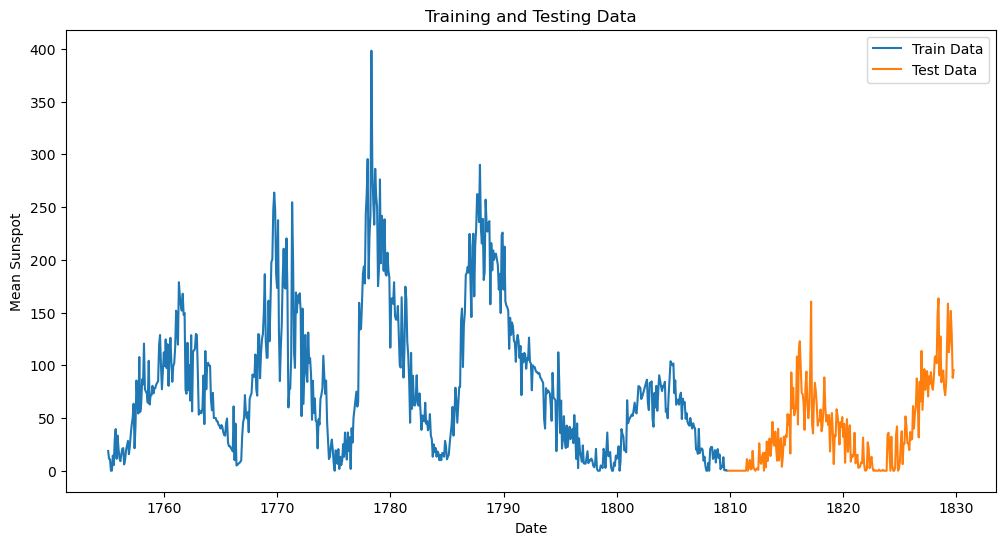

X_train shape: (537, 120)
y_train shape: (537,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 188ms/step - loss: 0.0649 - val_loss: 0.0048 - learning_rate: 0.0050
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - loss: 0.0231 - val_loss: 0.0025 - learning_rate: 0.0050
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step - loss: 0.0112 - val_loss: 0.0052 - learning_rate: 0.0050
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - loss: 0.0135 - val_loss: 0.0075 - learning_rate: 0.0050
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - loss: 0.0115 - val_loss: 0.0017 - learning_rate: 0.0050
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - loss: 0.0087 - val_loss: 0.0014 - learning_rate: 0.0050
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - loss: 0.0077 - val_loss: 0.0018 - learning_rate: 0.0050
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - loss: 0.0093 - val_loss: 0.0012 - learning_rate: 0.0050
Epoch 9/100
14/14 

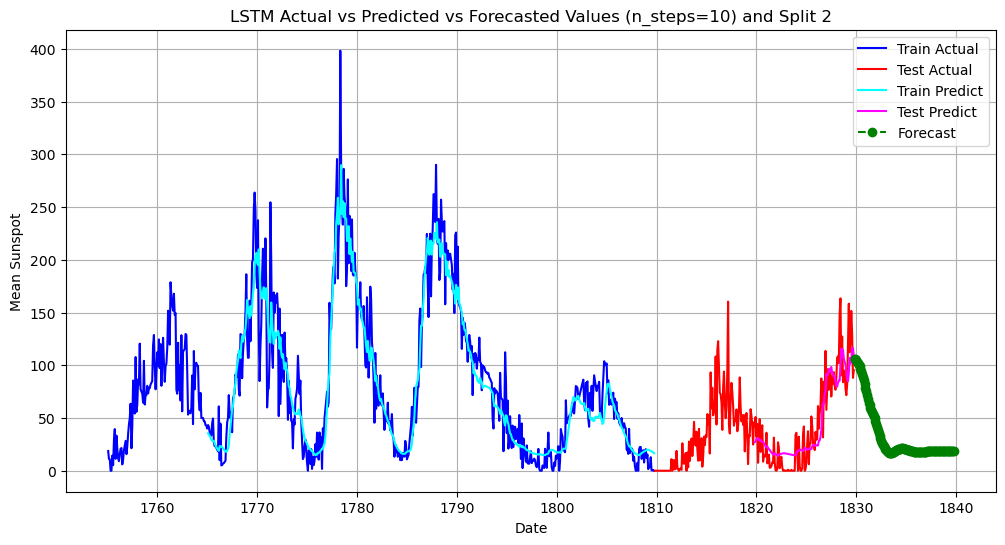

-----------------------------------3-----------------------------------
Scale train Dataset:  777
Scale test Dataset:  240


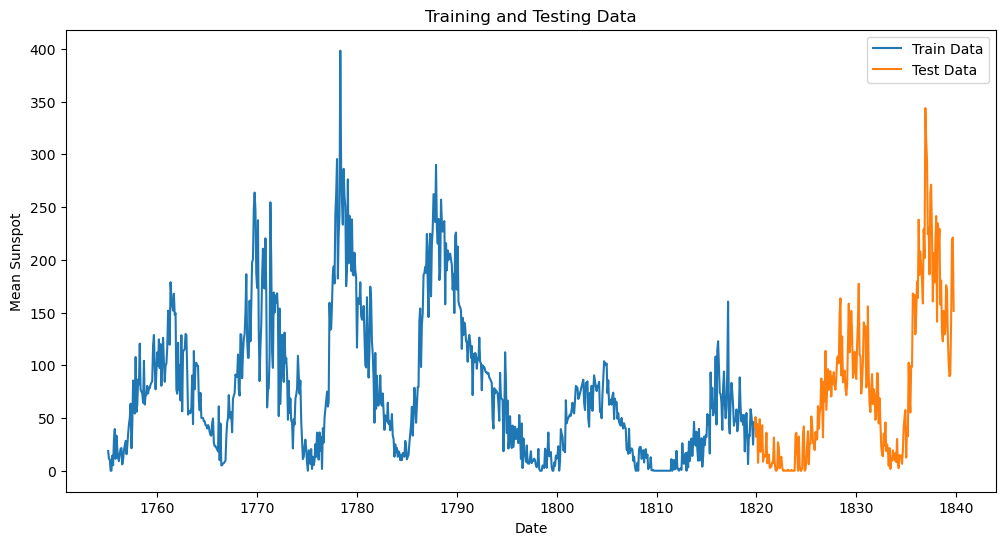

X_train shape: (657, 120)
y_train shape: (657,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 131ms/step - loss: 0.0375 - val_loss: 0.0078 - learning_rate: 0.0050
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - loss: 0.0127 - val_loss: 0.0025 - learning_rate: 0.0050
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - loss: 0.0089 - val_loss: 0.0053 - learning_rate: 0.0050
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - loss: 0.0101 - val_loss: 0.0024 - learning_rate: 0.0050
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - loss: 0.0078 - val_loss: 0.0025 - learning_rate: 0.0050
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - loss: 0.0086 - val_loss: 0.0024 - learning_rate: 0.0050
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - loss: 0.0066 - val_loss: 0.0025 - learning_rate: 0.0050
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 0.0063 - val_loss: 0.0026 - learning_rate: 0.0050
Epoch 9/100
17/17 ━━

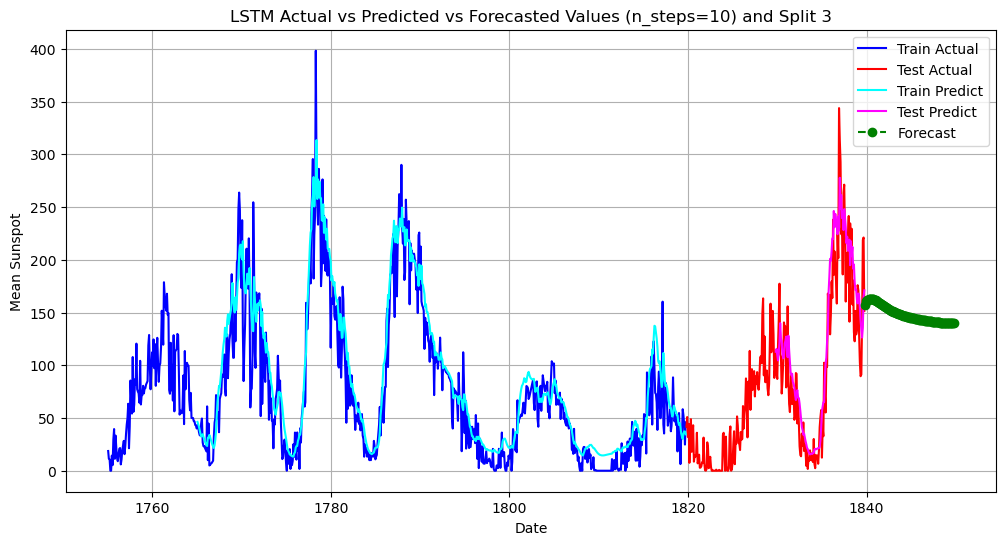

-----------------------------------4-----------------------------------
Scale train Dataset:  897
Scale test Dataset:  240


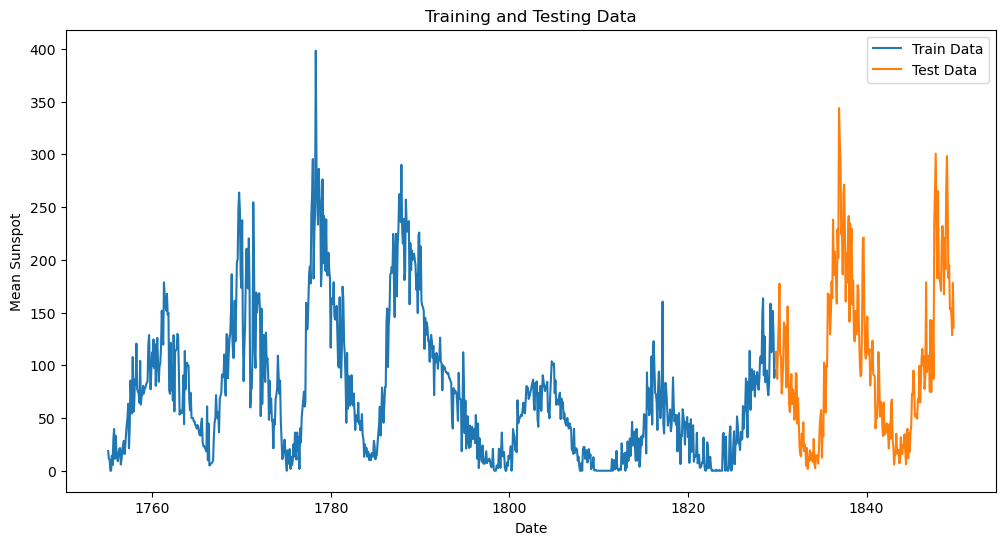

X_train shape: (777, 120)
y_train shape: (777,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 173ms/step - loss: 0.0358 - val_loss: 0.0048 - learning_rate: 0.0050
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - loss: 0.0090 - val_loss: 0.0037 - learning_rate: 0.0050
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - loss: 0.0072 - val_loss: 0.0033 - learning_rate: 0.0050
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - loss: 0.0081 - val_loss: 0.0029 - learning_rate: 0.0050
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - loss: 0.0061 - val_loss: 0.0039 - learning_rate: 0.0050
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - loss: 0.0064 - val_loss: 0.0029 - learning_rate: 0.0050
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - loss: 0.0061 - val_loss: 0.0033 - learning_rate: 0.0050
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 0.0060 - val_loss: 0.0029 - learning_rate: 0.0050
Epoch 9/100
20/20

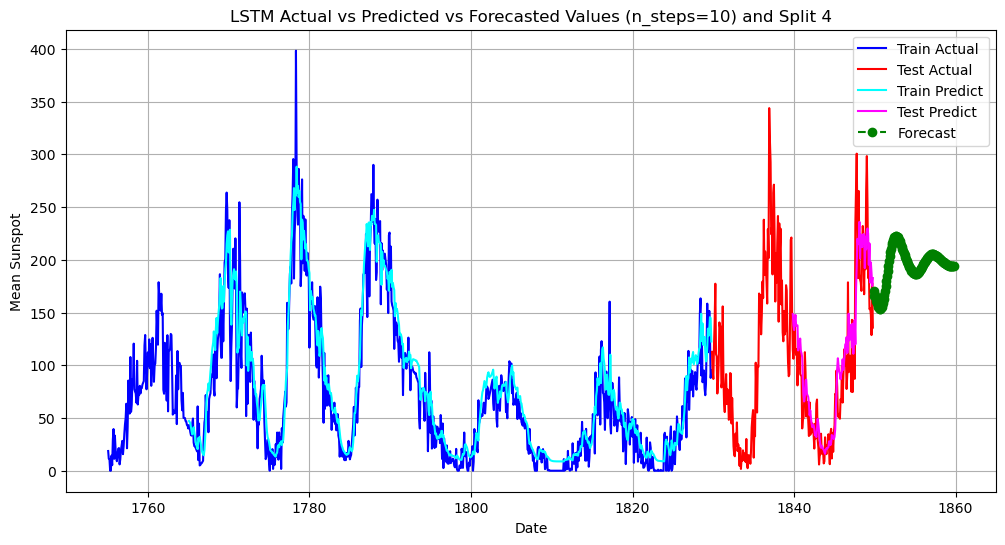

-----------------------------------5-----------------------------------
Scale train Dataset:  1017
Scale test Dataset:  240


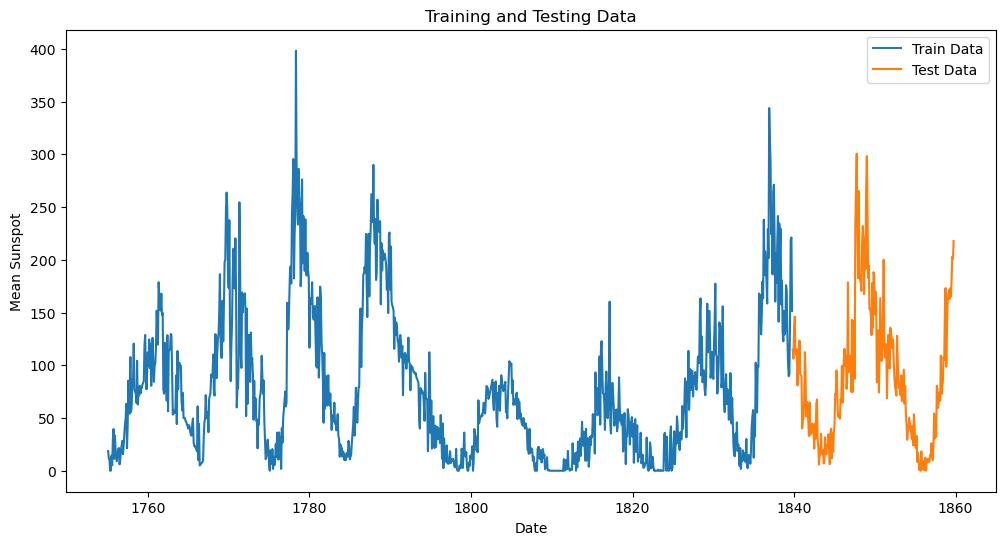

X_train shape: (897, 120)
y_train shape: (897,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 139ms/step - loss: 0.0235 - val_loss: 0.0105 - learning_rate: 0.0050
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - loss: 0.0087 - val_loss: 0.0104 - learning_rate: 0.0050
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - loss: 0.0070 - val_loss: 0.0091 - learning_rate: 0.0050
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - loss: 0.0066 - val_loss: 0.0108 - learning_rate: 0.0050
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - loss: 0.0055 - val_loss: 0.0095 - learning_rate: 0.0050
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - loss: 0.0055 - val_loss: 0.0078 - learning_rate: 0.0050
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - loss: 0.0057 - val_loss: 0.0101 - learning_rate: 0.0050
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - loss: 0.0057 - val_loss: 0.0087 - learning_rate: 0.0050
Epoch 9/100
23/23 ━━

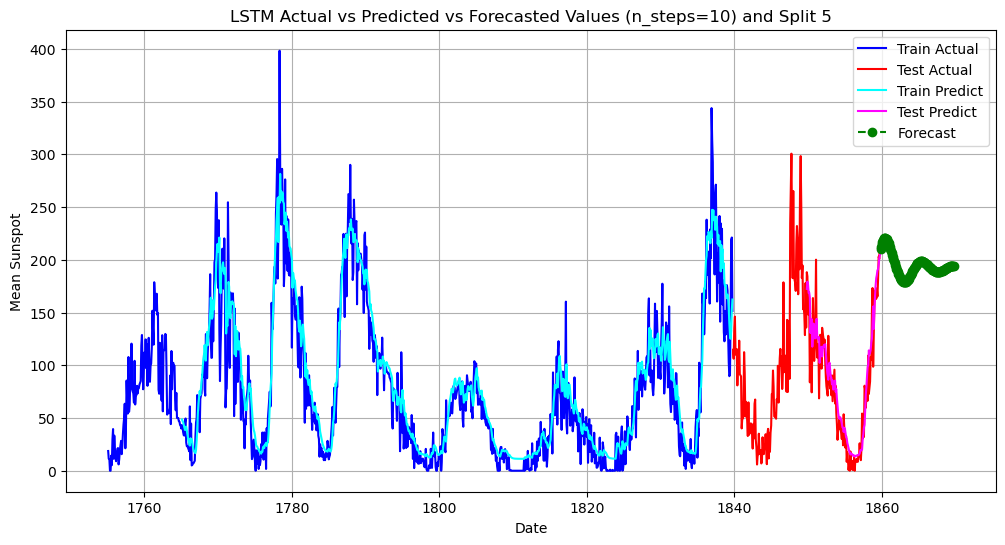

-----------------------------------6-----------------------------------
Scale train Dataset:  1137
Scale test Dataset:  240


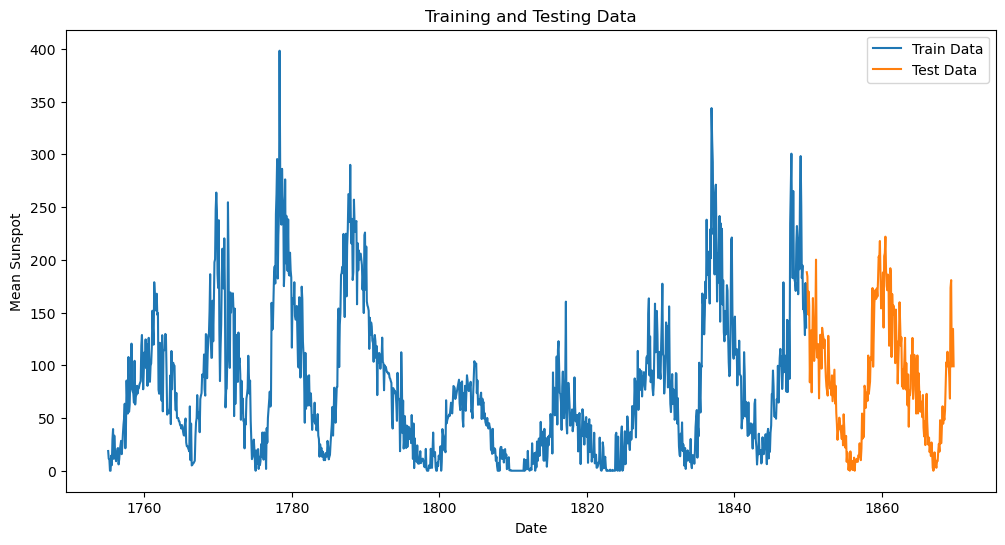

X_train shape: (1017, 120)
y_train shape: (1017,)
X_test shape: (120, 120)
y_test shape: (120,)
Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - loss: 0.0288 - val_loss: 0.0147 - learning_rate: 0.0050
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - loss: 0.0076 - val_loss: 0.0117 - learning_rate: 0.0050
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - loss: 0.0060 - val_loss: 0.0100 - learning_rate: 0.0050
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - loss: 0.0058 - val_loss: 0.0103 - learning_rate: 0.0050
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.0058 - val_loss: 0.0096 - learning_rate: 0.0050
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - loss: 0.0062 - val_loss: 0.0101 - learning_rate: 0.0050
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - loss: 0.0056 - val_loss: 0.0093 - learning_rate: 0.0050
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - loss: 0.0049 - val_loss: 0.0096 - learning_rate: 0.0050
Epoch 9/100
26/26 ━━━

In [ ]:
sample_years = [10]
for years in sample_years:
    expanding_windows_size = (years) * 12
    sample_taken = sample_size(years, total_num_months) + expanding_windows_size
    split_num = 1
    
    while sample_taken < len(df):
        print(f"-----------------------------------{split_num}-----------------------------------")
        sample_df = df[:sample_taken]
        x_size = sample_taken - expanding_windows_size
        column_name = 'mean_sunspot'
        train_data = df[:x_size]
        end_index = sample_taken + expanding_windows_size  # Corrected index
        test_data = df[x_size:end_index]
        calculate_lstm(train_data, test_data, column_name, years, expanding_windows_size, split_num)
        # calculate_xgboost(train_data, test_data, column_name, years, expanding_windows_size, split_num)
        # calculate_cnn(train_data, test_data, column_name, years, expanding_windows_size, split_num)
        split_num += 1
        sample_taken += expanding_windows_size